<a href="https://colab.research.google.com/github/JorgeMOntiverosL/MBIA2602-Fase1-Ontiveros/blob/main/MBIA_Fase2_Ontiveros_Visual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf

TAM = (224, 224)
BATCH = 16
RUTA = "/content/imagenes"

train_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/train", image_size=TAM, batch_size=BATCH, seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/val", image_size=TAM, batch_size=BATCH, seed=42
)
test_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/test", image_size=TAM, batch_size=BATCH,
  shuffle=False
)
clases = train_ds.class_names
print(clases)

Found 126 files belonging to 3 classes.
Found 27 files belonging to 3 classes.
Found 27 files belonging to 3 classes.
['Clase_1', 'Clase_2', 'Clase_3']


In [3]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base = ResNet50(weights="imagenet", include_top=False,
    input_shape=(224, 224, 3))
base.trainable = False

entrada = keras.Input(shape=(224, 224, 3))
x = layers.RandomFlip("horizontal")(entrada)
x = layers.RandomRotation(0.05)(x)
x = preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)
modelo_img = keras.Model(entrada, salida)

modelo_img.compile(optimizer=keras.optimizers.Adam(1e-3),
  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [4]:
parada = keras.callbacks.EarlyStopping(
  monitor="val_loss", patience=3, restore_best_weights=True)

historia = modelo_img.fit(
  train_ds, validation_data=val_ds, epochs=15,
  callbacks=[parada]
)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 470ms/step - accuracy: 0.3651 - loss: 1.4020 - val_accuracy: 0.8519 - val_loss: 0.5623
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.7143 - loss: 0.6835 - val_accuracy: 0.9630 - val_loss: 0.2636
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8333 - loss: 0.4144 - val_accuracy: 1.0000 - val_loss: 0.1419
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9127 - loss: 0.2272 - val_accuracy: 1.0000 - val_loss: 0.0886
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9683 - loss: 0.1502 - val_accuracy: 1.0000 - val_loss: 0.0626
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9762 - loss: 0.1292 - val_accuracy: 1.0000 - val_loss: 0.0605
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9841 - loss: 0.1090 - val_accuracy: 1.0000 - val_loss: 0.0455
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.9841 - loss: 0.0858 - val_accuracy: 1.0000 - val_loss: 0.033

In [7]:
import os
os.makedirs("/content/modelos", exist_ok=True)
modelo_img.save("/content/modelos/clasificador_imagenes.keras")

In [8]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_real = np.concatenate([y.numpy() for _, y in test_ds])
prob = modelo_img.predict(test_ds)
y_pred = np.argmax(prob, axis=1)
print(classification_report(y_real, y_pred, target_names=clases,
    zero_division=0))
print(confusion_matrix(y_real, y_pred))
modelo_img.save("/content/modelos/clasificador_imagenes.keras")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
              precision    recall  f1-score   support

     Clase_1       1.00      1.00      1.00         9
     Clase_2       1.00      1.00      1.00         9
     Clase_3       1.00      1.00      1.00         9

    accuracy                           1.00        27
   macro avg       1.00      1.00      1.00        27
weighted avg       1.00      1.00      1.00        27

[[9 0 0]
 [0 9 0]
 [0 0 9]]


Saving res prueba 1.jpg to res prueba 1 (1).jpg


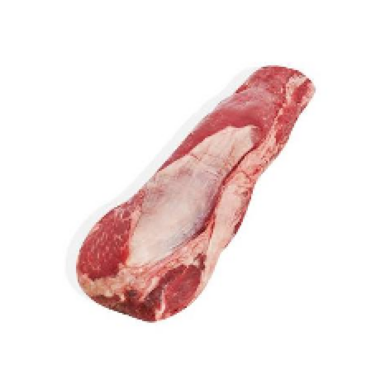

Tipo de proteína: Clase_1
Confianza: 0.925
  Clase_1: 0.925
  Clase_2: 0.056
  Clase_3: 0.019


In [18]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

subidos = files.upload()
ruta = list(subidos.keys())[0]

img = keras.utils.load_img(ruta, target_size=(224, 224))
imagen_lista = np.expand_dims(keras.utils.img_to_array(img), axis=0)

probabilidades = modelo_img.predict(imagen_lista, verbose=0)[0]
indice = int(np.argmax(probabilidades))

plt.imshow(img); plt.axis("off"); plt.show()
print("Tipo de proteína:", clases[indice])
print("Confianza:", round(float(probabilidades[indice]), 3))
for nombre, p in zip(clases, probabilidades):
    print(f"  {nombre}: {p:.3f}")